In [1]:
import os
import json
import math
import random
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

OUTPUT_DIR = "/kaggle/working/drone_route_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Drone Delivery Route Optimization")
print("Algorithm: Genetic Algorithm")
print("Libraries loaded successfully.")
print("Output folder:", OUTPUT_DIR)

Drone Delivery Route Optimization
Algorithm: Genetic Algorithm
Libraries loaded successfully.
Output folder: /kaggle/working/drone_route_results


In [2]:
dataset_path = None

preferred_files = [
    "redundancy.in",
    "mother_of_all_warehouses.in"
]

for preferred in preferred_files:
    for root, dirs, file_names in os.walk("/kaggle/input"):
        if preferred in file_names:
            dataset_path = os.path.join(root, preferred)
            break
    if dataset_path is not None:
        break

if dataset_path is None:
    print("Available files:")
    for root, dirs, file_names in os.walk("/kaggle/input"):
        for name in file_names:
            print(os.path.join(root, name))

    raise FileNotFoundError(
        "Dataset not found. Use Add Input to attach the Google Drone Delivery dataset."
    )

print("Dataset found:", dataset_path)
print("File size:", round(os.path.getsize(dataset_path) / 1024, 2), "KB")

Dataset found: /kaggle/input/datasets/pranithchowdary/google-drone-delivery/redundancy.in
File size: 110.91 KB


In [3]:
with open(dataset_path, "r") as f:
    tokens = list(map(int, f.read().split()))

it = iter(tokens)

rows = next(it)
cols = next(it)
num_drones = next(it)
num_turns = next(it)
max_payload = next(it)

num_products = next(it)
product_weights = [next(it) for _ in range(num_products)]

num_warehouses = next(it)
warehouses = []

for _ in range(num_warehouses):
    r, c = next(it), next(it)
    inventory = [next(it) for _ in range(num_products)]

    warehouses.append({
        "row": r,
        "col": c,
        "inventory": inventory
    })

num_orders = next(it)
orders = []

for order_id in range(num_orders):
    r, c = next(it), next(it)
    item_count = next(it)
    items = [next(it) for _ in range(item_count)]

    orders.append({
        "order_id": order_id,
        "row": r,
        "col": c,
        "items": items
    })

print("DATASET DETAILS")
print("-" * 40)
print("File:", os.path.basename(dataset_path))
print("Grid dimensions:", rows, "x", cols)
print("Number of drones:", num_drones)
print("Deadline in turns:", num_turns)
print("Maximum drone payload:", max_payload)
print("Product types:", num_products)
print("Warehouses:", num_warehouses)
print("Customer orders:", num_orders)
print("Total requested items:", sum(len(o["items"]) for o in orders))

DATASET DETAILS
----------------------------------------
File: redundancy.in
Grid dimensions: 300 x 500
Number of drones: 30
Deadline in turns: 145416
Maximum drone payload: 200
Product types: 2000
Warehouses: 16
Customer orders: 1000
Total requested items: 7444


In [4]:
warehouse_df = pd.DataFrame([
    {
        "warehouse_id": i,
        "row": w["row"],
        "col": w["col"],
        "total_stock_items": sum(w["inventory"])
    }
    for i, w in enumerate(warehouses)
])

order_df = pd.DataFrame([
    {
        "order_id": o["order_id"],
        "row": o["row"],
        "col": o["col"],
        "item_count": len(o["items"]),
        "total_weight": sum(product_weights[p] for p in o["items"])
    }
    for o in orders
])

print("WAREHOUSE SUMMARY")
display(warehouse_df.head(10))

print("ORDER SUMMARY")
display(order_df.head(10))

print("Orders exceeding single-drone payload:",
      int((order_df["total_weight"] > max_payload).sum()))

print("Average items per order:",
      round(order_df["item_count"].mean(), 2))

print("Average order weight:",
      round(order_df["total_weight"].mean(), 2))

warehouse_df.to_csv(
    os.path.join(OUTPUT_DIR, "warehouse_summary.csv"),
    index=False
)

order_df.to_csv(
    os.path.join(OUTPUT_DIR, "order_summary.csv"),
    index=False
)

WAREHOUSE SUMMARY


,warehouse_id,row,col,total_stock_items
0,0,35,241,4604
1,1,39,301,4672
2,2,248,448,4667
3,3,232,324,4463
4,4,156,185,4505
5,5,13,264,4574
6,6,68,401,4614
7,7,236,190,4566
8,8,176,370,4468
9,9,228,348,4565


ORDER SUMMARY


,order_id,row,col,item_count,total_weight
0,0,106,165,11,561
1,1,66,324,8,489
2,2,107,128,6,561
3,3,165,160,7,433
4,4,193,198,12,705
5,5,227,219,5,315
6,6,111,241,7,411
7,7,190,191,3,128
8,8,114,348,2,79
9,9,46,114,11,662


Orders exceeding single-drone payload: 811
Average items per order: 7.44
Average order weight: 469.04


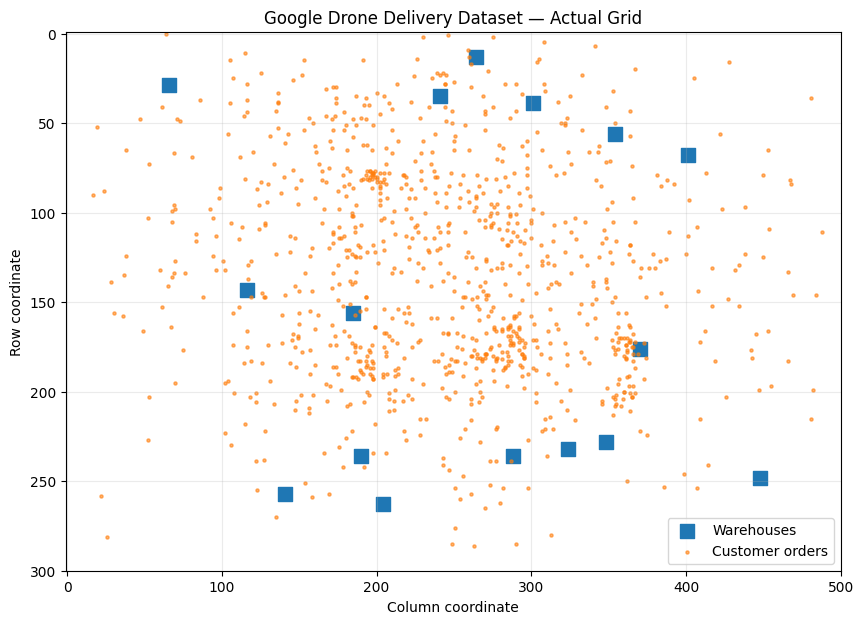

In [5]:
plt.figure(figsize=(10, 7))

plt.scatter(
    [w["col"] for w in warehouses],
    [w["row"] for w in warehouses],
    marker="s",
    s=100,
    label="Warehouses"
)

plt.scatter(
    [o["col"] for o in orders],
    [o["row"] for o in orders],
    marker=".",
    s=20,
    alpha=0.6,
    label="Customer orders"
)

plt.xlim(-1, cols)
plt.ylim(rows, -1)
plt.xlabel("Column coordinate")
plt.ylabel("Row coordinate")
plt.title("Google Drone Delivery Dataset — Actual Grid")
plt.legend()
plt.grid(alpha=0.25)

plt.savefig(
    os.path.join(OUTPUT_DIR, "dataset_grid.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [6]:
MAX_SELECTED_ORDERS = 10

def order_requirements(order):
    required = [0] * num_products

    for product_id in order["items"]:
        required[product_id] += 1

    weight = sum(
        product_weights[p] * required[p]
        for p in range(num_products)
    )

    return required, weight


best_selection = []

for warehouse_id, warehouse in enumerate(warehouses):
    remaining_stock = warehouse["inventory"].copy()
    remaining_payload = max_payload
    candidate_selection = []

    for order in orders:
        required, weight = order_requirements(order)

        if weight > remaining_payload:
            continue

        if any(
            required[p] > remaining_stock[p]
            for p in range(num_products)
        ):
            continue

        candidate_selection.append(order)

        remaining_payload -= weight

        for p in range(num_products):
            remaining_stock[p] -= required[p]

        if len(candidate_selection) >= MAX_SELECTED_ORDERS:
            break

    if len(candidate_selection) > len(best_selection):
        best_selection = candidate_selection
        selected_warehouse_id = warehouse_id

if not best_selection:
    raise ValueError(
        "No feasible orders found. Check the dataset and warehouse inventories."
    )

selected_orders = best_selection
selected_warehouse = warehouses[selected_warehouse_id]

start = (selected_warehouse["row"], selected_warehouse["col"])

locations = [
    (order["row"], order["col"])
    for order in selected_orders
]

total_selected_weight = sum(
    order_requirements(order)[1]
    for order in selected_orders
)

print("Selected warehouse:", selected_warehouse_id)
print("Warehouse coordinate:", start)
print("Feasible orders selected:", len(selected_orders))
print("Selected order IDs:", [o["order_id"] for o in selected_orders])
print("Total payload weight:", total_selected_weight)
print("Maximum payload:", max_payload)

assert total_selected_weight <= max_payload

Selected warehouse: 0
Warehouse coordinate: (35, 241)
Feasible orders selected: 3
Selected order IDs: [8, 14, 115]
Total payload weight: 195
Maximum payload: 200


In [7]:
def euclidean(a, b):
    return math.sqrt(
        (a[0] - b[0]) ** 2 +
        (a[1] - b[1]) ** 2
    )


def route_distance(route):
    if not route:
        return 0.0

    total = euclidean(start, locations[route[0]])

    for i in range(len(route) - 1):
        total += euclidean(
            locations[route[i]],
            locations[route[i + 1]]
        )

    total += euclidean(locations[route[-1]], start)

    return total


def estimated_flight_turns(route):
    if not route:
        return 0

    points = [start] + [
        locations[i] for i in route
    ] + [start]

    return sum(
        math.ceil(euclidean(points[i], points[i + 1]))
        for i in range(len(points) - 1)
    )


# The baseline visits selected orders in their original dataset order.
original_route = list(range(len(selected_orders)))

print("Baseline route distance:",
      round(route_distance(original_route), 2), "grid units")

print("Baseline estimated flight turns:",
      estimated_flight_turns(original_route))

Baseline route distance: 591.23 grid units
Baseline estimated flight turns: 594


In [8]:
POPULATION_SIZE = 80
GENERATIONS = 150
MUTATION_RATE = 0.15
ELITE_COUNT = 2

n = len(selected_orders)


def tournament_selection(population, k=4):
    candidates = random.sample(
        population,
        min(k, len(population))
    )
    return min(candidates, key=route_distance)


def order_crossover(parent1, parent2):
    size = len(parent1)

    if size < 2:
        return parent1.copy()

    left, right = sorted(random.sample(range(size), 2))

    child = [None] * size
    child[left:right + 1] = parent1[left:right + 1]

    remaining = [
        item for item in parent2
        if item not in child
    ]

    empty_positions = [
        i for i, item in enumerate(child)
        if item is None
    ]

    for position, item in zip(empty_positions, remaining):
        child[position] = item

    return child


def mutate(route):
    route = route.copy()

    if len(route) >= 2 and random.random() < MUTATION_RATE:
        i, j = random.sample(range(len(route)), 2)
        route[i], route[j] = route[j], route[i]

    return route


population = [
    random.sample(range(n), n)
    for _ in range(POPULATION_SIZE)
]

# Keep the baseline route as an initial candidate.
population[0] = original_route.copy()

best_route = original_route.copy()
best_distance = route_distance(best_route)
history = []

for generation in range(GENERATIONS):
    population.sort(key=route_distance)

    if route_distance(population[0]) < best_distance:
        best_route = population[0].copy()
        best_distance = route_distance(best_route)

    history.append(best_distance)

    next_population = [
        route.copy()
        for route in population[:ELITE_COUNT]
    ]

    while len(next_population) < POPULATION_SIZE:
        parent1 = tournament_selection(population)
        parent2 = tournament_selection(population)

        child = order_crossover(parent1, parent2)
        child = mutate(child)

        next_population.append(child)

    population = next_population

optimized_route = best_route.copy()

print("Genetic Algorithm completed.")
print("Best distance:", round(route_distance(optimized_route), 2),
      "grid units")
print("Optimized estimated flight turns:",
      estimated_flight_turns(optimized_route))

Genetic Algorithm completed.
Best distance: 535.02 grid units
Optimized estimated flight turns: 537


In [9]:
original_distance = route_distance(original_route)
optimized_distance = route_distance(optimized_route)

original_turns = estimated_flight_turns(original_route)
optimized_turns = estimated_flight_turns(optimized_route)

improvement_percent = (
    (original_distance - optimized_distance) / original_distance * 100
    if original_distance > 0 else 0
)

turn_improvement_percent = (
    (original_turns - optimized_turns) / original_turns * 100
    if original_turns > 0 else 0
)

results = {
    "dataset_file": os.path.basename(dataset_path),
    "grid_rows": rows,
    "grid_columns": cols,
    "total_dataset_orders": num_orders,
    "total_warehouses": num_warehouses,
    "selected_warehouse_id": selected_warehouse_id,
    "selected_order_ids": [
        order["order_id"] for order in selected_orders
    ],
    "selected_order_count": len(selected_orders),
    "total_selected_payload_weight": total_selected_weight,
    "maximum_payload": max_payload,
    "population_size": POPULATION_SIZE,
    "generations": GENERATIONS,
    "mutation_rate": MUTATION_RATE,
    "original_distance_grid_units": round(original_distance, 3),
    "optimized_distance_grid_units": round(optimized_distance, 3),
    "distance_improvement_percent": round(improvement_percent, 2),
    "original_estimated_flight_turns": original_turns,
    "optimized_estimated_flight_turns": optimized_turns,
    "estimated_turn_improvement_percent": round(
        turn_improvement_percent, 2
    ),
    "distance_metric": "Euclidean grid distance",
    "route_definition": "Warehouse to selected orders and back",
    "limitations": [
        "Optimizes the order of a single selected trip",
        "Uses grid coordinates, not GPS coordinates",
        "Does not simulate drone schedules or multiple drones",
        "Does not calculate the full original challenge score"
    ]
}

print("ROUTE COMPARISON")
print("-" * 45)
print(f"Original distance:   {original_distance:.2f} grid units")
print(f"Optimized distance:  {optimized_distance:.2f} grid units")
print(f"Distance reduction:  {improvement_percent:.2f}%")
print()
print(f"Original estimated turns:  {original_turns}")
print(f"Optimized estimated turns: {optimized_turns}")
print(f"Estimated turn reduction:  {turn_improvement_percent:.2f}%")

display(pd.DataFrame([
    {
        "Metric": "Route distance (grid units)",
        "Original": round(original_distance, 2),
        "GA optimized": round(optimized_distance, 2)
    },
    {
        "Metric": "Estimated flight turns",
        "Original": original_turns,
        "GA optimized": optimized_turns
    },
    {
        "Metric": "Orders visited",
        "Original": len(original_route),
        "GA optimized": len(optimized_route)
    }
]))

print("\nDetailed results:")
print(json.dumps(results, indent=2))

ROUTE COMPARISON
---------------------------------------------
Original distance:   591.23 grid units
Optimized distance:  535.02 grid units
Distance reduction:  9.51%

Original estimated turns:  594
Optimized estimated turns: 537
Estimated turn reduction:  9.60%


,Metric,Original,GA optimized
0,Route distance (grid units),591.23,535.02
1,Estimated flight turns,594.00,537.00
2,Orders visited,3.00,3.00



Detailed results:
{
  "dataset_file": "redundancy.in",
  "grid_rows": 300,
  "grid_columns": 500,
  "total_dataset_orders": 1000,
  "total_warehouses": 16,
  "selected_warehouse_id": 0,
  "selected_order_ids": [
    8,
    14,
    115
  ],
  "selected_order_count": 3,
  "total_selected_payload_weight": 195,
  "maximum_payload": 200,
  "population_size": 80,
  "generations": 150,
  "mutation_rate": 0.15,
  "original_distance_grid_units": 591.234,
  "optimized_distance_grid_units": 535.02,
  "distance_improvement_percent": 9.51,
  "original_estimated_flight_turns": 594,
  "optimized_estimated_flight_turns": 537,
  "estimated_turn_improvement_percent": 9.6,
  "distance_metric": "Euclidean grid distance",
  "route_definition": "Warehouse to selected orders and back",
  "limitations": [
    "Optimizes the order of a single selected trip",
    "Uses grid coordinates, not GPS coordinates",
    "Does not simulate drone schedules or multiple drones",
    "Does not calculate the full original c

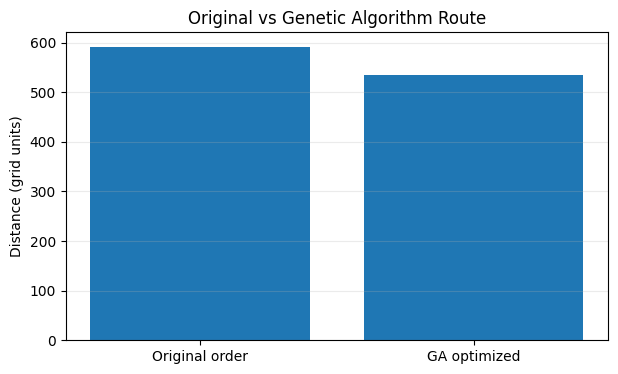

In [10]:
plt.figure(figsize=(7, 4))

plt.bar(
    ["Original order", "GA optimized"],
    [original_distance, optimized_distance]
)

plt.ylabel("Distance (grid units)")
plt.title("Original vs Genetic Algorithm Route")
plt.grid(axis="y", alpha=0.25)

plt.savefig(
    os.path.join(OUTPUT_DIR, "distance_comparison.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

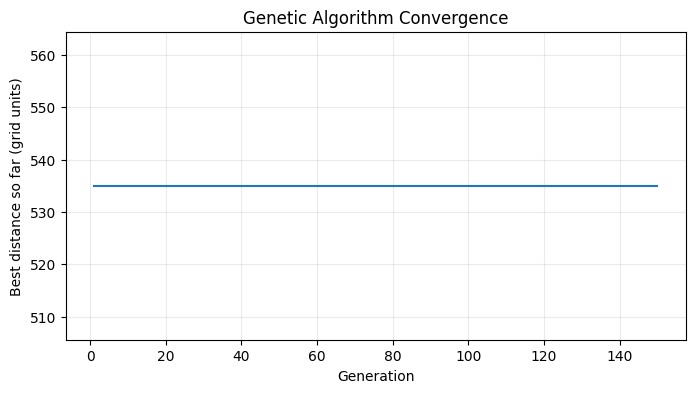

Initial best distance: 535.02
Final best distance: 535.02


In [11]:
plt.figure(figsize=(8, 4))

plt.plot(
    range(1, len(history) + 1),
    history
)

plt.xlabel("Generation")
plt.ylabel("Best distance so far (grid units)")
plt.title("Genetic Algorithm Convergence")
plt.grid(alpha=0.25)

plt.savefig(
    os.path.join(OUTPUT_DIR, "ga_convergence.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Initial best distance:", round(history[0], 2))
print("Final best distance:", round(history[-1], 2))

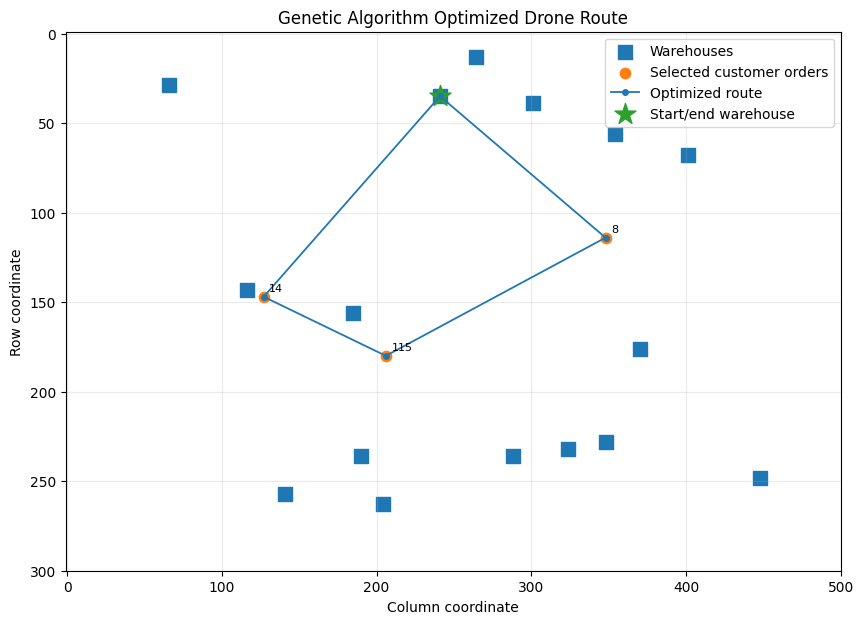

In [12]:
route_points = [start] + [
    locations[i] for i in optimized_route
] + [start]

route_rows = [point[0] for point in route_points]
route_cols = [point[1] for point in route_points]

plt.figure(figsize=(10, 7))

plt.scatter(
    [w["col"] for w in warehouses],
    [w["row"] for w in warehouses],
    marker="s",
    s=100,
    label="Warehouses"
)

plt.scatter(
    [order["col"] for order in selected_orders],
    [order["row"] for order in selected_orders],
    marker="o",
    s=55,
    label="Selected customer orders"
)

plt.plot(
    route_cols,
    route_rows,
    "-o",
    markersize=4,
    linewidth=1.3,
    label="Optimized route"
)

plt.scatter(
    start[1],
    start[0],
    marker="*",
    s=250,
    label="Start/end warehouse"
)

for sequence, route_index in enumerate(optimized_route, start=1):
    r, c = locations[route_index]
    order_id = selected_orders[route_index]["order_id"]
    plt.annotate(
        str(order_id),
        (c, r),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

plt.xlim(-1, cols)
plt.ylim(rows, -1)
plt.xlabel("Column coordinate")
plt.ylabel("Row coordinate")
plt.title("Genetic Algorithm Optimized Drone Route")
plt.legend()
plt.grid(alpha=0.25)

plt.savefig(
    os.path.join(OUTPUT_DIR, "optimized_grid_route.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [13]:
route_records = []

for sequence, route_index in enumerate(optimized_route, start=1):
    order = selected_orders[route_index]

    route_records.append({
        "visit_sequence": sequence,
        "order_id": order["order_id"],
        "row": order["row"],
        "col": order["col"],
        "item_count": len(order["items"]),
        "order_weight": order_requirements(order)[1]
    })

route_df = pd.DataFrame(route_records)

route_csv = os.path.join(OUTPUT_DIR, "optimized_route.csv")
route_df.to_csv(route_csv, index=False)

print("OPTIMIZED VISIT SEQUENCE")
display(route_df)

print("Saved:", route_csv)

OPTIMIZED VISIT SEQUENCE


,visit_sequence,order_id,row,col,item_count,order_weight
0,1,14,147,127,1,99
1,2,115,180,206,1,17
2,3,8,114,348,2,79


Saved: /kaggle/working/drone_route_results/optimized_route.csv


In [14]:
config = {
    "project": "Drone Delivery Route Optimization",
    "algorithm": "Genetic Algorithm",
    "dataset_file": os.path.basename(dataset_path),
    "coordinate_type": "Grid row and column",
    "distance_unit": "Grid units",
    "warehouse_id": selected_warehouse_id,
    "warehouse_coordinate": list(start),
    "selected_order_ids": [
        order["order_id"] for order in selected_orders
    ],
    "population_size": POPULATION_SIZE,
    "generations": GENERATIONS,
    "mutation_rate": MUTATION_RATE,
    "elite_count": ELITE_COUNT,
    "random_seed": SEED
}

with open(os.path.join(OUTPUT_DIR, "route_config.json"), "w") as f:
    json.dump(config, f, indent=2)

with open(os.path.join(OUTPUT_DIR, "experiment_results.json"), "w") as f:
    json.dump(results, f, indent=2)

convergence_df = pd.DataFrame({
    "generation": range(1, len(history) + 1),
    "best_distance_grid_units": history
})

convergence_df.to_csv(
    os.path.join(OUTPUT_DIR, "ga_convergence.csv"),
    index=False
)

selected_df = pd.DataFrame([
    {
        "order_id": order["order_id"],
        "row": order["row"],
        "col": order["col"],
        "item_count": len(order["items"]),
        "weight": order_requirements(order)[1]
    }
    for order in selected_orders
])

selected_df.to_csv(
    os.path.join(OUTPUT_DIR, "selected_orders.csv"),
    index=False
)

print("Configuration, evaluation, and route files saved.")

Configuration, evaluation, and route files saved.


In [15]:
zip_path = "/kaggle/working/drone_route_stage1.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, file_names in os.walk(OUTPUT_DIR):
        for name in file_names:
            full_path = os.path.join(root, name)
            relative_path = os.path.relpath(full_path, OUTPUT_DIR)
            z.write(full_path, arcname=relative_path)

print("ZIP created:", zip_path)
print("ZIP size:", round(os.path.getsize(zip_path) / 1024, 2), "KB")

print("\nFiles included:")
with zipfile.ZipFile(zip_path, "r") as z:
    for name in z.namelist():
        print("-", name)

from IPython.display import FileLink, display
display(FileLink(zip_path))

ZIP created: /kaggle/working/drone_route_stage1.zip
ZIP size: 205.87 KB

Files included:
- dataset_grid.png
- ga_convergence.png
- optimized_route.csv
- route_config.json
- experiment_results.json
- selected_orders.csv
- ga_convergence.csv
- distance_comparison.png
- warehouse_summary.csv
- order_summary.csv
- optimized_grid_route.png


/kaggle/working/drone_route_stage1.zip